# 00 · Environment and sanity checks

**AI631 project: QSVM for RC column capacity checks under biaxial bending** (Rohan Imtiaz, 25280058)

Run this notebook first. It does not train anything. It checks that:

1. the course environment (Qiskit 2.x, Aer, IBM Runtime) is installed,
2. the dataset files are where the project expects them,
3. the project capacity code reproduces your SAFE / UNSAFE labels (needed for the boundary band metric and for the two extra sections),
4. the exact NumPy kernels match Qiskit `Statevector` for every feature map used later,
5. the sampled kernel on `AerSimulator` agrees with the exact kernel within shot noise,
6. the noisy simulator and a fake IBM device load.

If any check prints **FAIL**, stop and send me the output.

In [1]:
# Make the project helper package (qsvm_rc) importable from any sub-folder
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "qsvm_rc").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: /kaggle/working/Project


## 1. Versions

In [2]:
import platform

import matplotlib
import numpy as np
import pandas as pd
import qiskit
import qiskit_aer
import qiskit_ibm_runtime
import scipy
import sklearn

print("python             ", platform.python_version())
print("qiskit             ", qiskit.__version__)
print("qiskit-aer         ", qiskit_aer.__version__)
print("qiskit-ibm-runtime ", qiskit_ibm_runtime.__version__)
print("numpy              ", np.__version__)
print("scipy              ", scipy.__version__)
print("scikit-learn       ", sklearn.__version__)
print("pandas             ", pd.__version__)
print("matplotlib         ", matplotlib.__version__)

assert qiskit.__version__.startswith("2."), "This project needs Qiskit 2.x"

python              3.13.18
qiskit              2.6.2
qiskit-aer          0.18.4
qiskit-ibm-runtime  0.52.1
numpy               2.1.3
scipy               1.16.3
scikit-learn        1.6.1
pandas              2.3.3
matplotlib          3.10.0


In [3]:
from qsvm_rc import config, data_utils, metrics, quantum_kernels, rc_capacity

print("Seed:", config.SEED)
print("Training sizes:", config.TRAIN_SIZES, " seeds:", config.TRAIN_SEEDS)
print("Sections:", {key: value["title"] for key, value in config.SECTIONS.items()})

Seed: 0
Training sizes: [20, 40, 80, 160, 320]  seeds: [0, 1, 2, 3, 4]
Sections: {'3x2': '3 ft x 2 ft (main)', '3x3': '3 ft x 3 ft (ablation)', '5x2_5': '5 ft x 2.5 ft (ablation)'}


## 2. Dataset files

In [4]:
main_section = config.SECTIONS[config.MAIN_SECTION]
for label, path in [("main dataset", main_section["dataset_path"]),
                    ("extended dataset", main_section["extended_path"]),
                    ("data generation notebook", config.PROJECT_ROOT / "data_generation.ipynb")]:
    status = "OK  " if path.exists() else "MISSING"
    print(f"{status} {label:<26} {path.name}")

assert main_section["dataset_path"].exists(), "FAIL: the main dataset must sit in the Project folder"

OK   main dataset               25280058_AI631_Project_Dataset.csv
OK   extended dataset           25280058_AI631_Project_Dataset_Extended.csv
OK   data generation notebook   data_generation.ipynb


In [5]:
# Column names as stored, and how the project maps them
raw_head = pd.read_csv(main_section["dataset_path"], nrows = 5)
print("Main dataset columns:", list(raw_head.columns))
print(data_utils.standardise_columns(raw_head).head())

if main_section["extended_path"].exists():
    print("\nExtended dataset columns:", list(pd.read_csv(main_section["extended_path"], nrows = 2).columns))

Main dataset columns: ['pu_kN', 'ex_mm', 'ey_mm', 'status']
   pu_kN  ex_mm  ey_mm status
0   1000    0.0    0.0   SAFE
1   1250    0.0    0.0   SAFE
2   1500    0.0    0.0   SAFE
3   1750    0.0    0.0   SAFE
4   2000    0.0    0.0   SAFE

Extended dataset columns: ['sr_no', 'pu_kN', 'ex_mm', 'ey_mm', 'column_dim_x_mm', 'column_dim_y_mm', 'fc_prime_MPa', 'fy_MPa', 'cover_to_bar_centroid_mm', 'number_of_bars', 'bar_number', 'bar_area_mm2', 'bar_diameter_mm', 'gross_area_mm2', 'steel_area_mm2', 'steel_ratio', 'beta_1', 'axial_capacity_P0_kN', 'axial_capacity_Pnx_kN', 'neutral_axis_x_mm', 'axial_capacity_Pny_kN', 'neutral_axis_y_mm', 'biaxial_capacity_Pni_kN', 'reciprocal_method_valid', 'phi', 'phi_Pni_kN', 'utilization_ratio', 'status']


## 3. Does the project capacity code reproduce your labels?

The project code (`qsvm_rc/rc_capacity.py`) uses strain compatibility with the ACI stress block
($\beta_1$ from ACI 318-19, $\varepsilon_{cu} = 0.003$, $E_s = 200$ GPa, displaced concrete subtracted)
and the Bresler reciprocal load method with $\phi = 0.65$. It is only used for

* the ratio $r = P_u / \phi P_{ni}$ that defines the boundary band (if the extended file has no $\phi P_{ni}$ column),
* the true boundary line in the ex-ey plots,
* generating the two extra sections.

Your labels are never replaced. An agreement above 99.5 percent means the band and the plots are consistent with your data.

In [6]:
frame_code = data_utils.load_section(config.MAIN_SECTION, capacity_source = "code")
agreement_code = data_utils.label_agreement(frame_code)
safe_fraction = np.mean(frame_code["label"] == 1)
print(f"Rows: {len(frame_code):,}   SAFE fraction: {safe_fraction:.4f}")
print(f"Label agreement, project capacity code: {agreement_code:.5f}")

# Same check without subtracting the displaced concrete, in case your generator did not subtract it
capacity_plain = rc_capacity.biaxial_capacity(main_section, frame_code["ex_mm"], frame_code["ey_mm"],
                                              subtract_displaced_concrete = False)
implied_plain = np.where(frame_code["pu_kN"] <= capacity_plain["phi_pni_kN"], 1, -1)
agreement_plain = np.mean(implied_plain == frame_code["label"])
print(f"Label agreement, no displaced concrete:  {agreement_plain:.5f}")

print("PASS" if agreement_code > 0.995 else "CHECK: agreement below 99.5 percent, send me this output")

Rows: 170,660   SAFE fraction: 0.3150
Label agreement, project capacity code: 0.99999
Label agreement, no displaced concrete:  0.98812
PASS


In [7]:
# Capacity source the other notebooks will use (extended file if a phi Pni column is recognised)
frame_auto = data_utils.load_section(config.MAIN_SECTION)
print("Capacity source:", frame_auto.attrs["capacity_source"])
print(f"Label agreement with that source: {data_utils.label_agreement(frame_auto):.5f}")

disagreeing = frame_code[np.where(frame_code["ratio"] <= 1, 1, -1) != frame_code["label"]]
print(f"\nRows where the project code disagrees with your label: {len(disagreeing)}")
print(disagreeing.head(10))

Capacity source: extended column 'phi_Pni_kN'
Label agreement with that source: 1.00000

Rows where the project code disagrees with your label: 1
       pu_kN  ex_mm  ey_mm  status  label  phi_pni_kN     ratio
14379   5000   50.0  280.0  UNSAFE     -1  5000.82744  0.999835


In [8]:
constants = rc_capacity.section_constants(main_section)
for name, value in constants.items():
    print(f"{name:<18} {value:,.4f}" if isinstance(value, float) else f"{name:<18} {value}")

number_of_bars     22
gross_area_mm2     557,418.2400
steel_area_mm2     18018
steel_ratio        0.0323
p0_kN              21,322.2661
phi_p0_kN          13,859.4730
bresler_limit_kN   1,672.2547
beta1              0.8357


## 4. Exact NumPy kernels against Qiskit `Statevector`

Noiseless kernels in this project are computed exactly from state vectors (synopsis, section VI). For three qubits the
state has 8 amplitudes, so the NumPy version in `quantum_kernels.exact_states` is exact and very fast.
This cell checks it against Qiskit's own circuits for every feature map used later.

In [9]:
from qiskit.quantum_info import Statevector

specs_to_check = [
    {"kind": "angle"},
    {"kind": "z", "reps": 1},
    {"kind": "z", "reps": 2},
    {"kind": "zz", "reps": 1, "entanglement": "linear"},
    {"kind": "zz", "reps": 2, "entanglement": "linear"},
    {"kind": "zz", "reps": 3, "entanglement": "linear"},
    {"kind": "zz", "reps": 1, "entanglement": "full"},
    {"kind": "zz", "reps": 2, "entanglement": "full"},
    {"kind": "pauli_zzz", "reps": 1, "entanglement": "full"},
]
check_rng = np.random.default_rng(config.SEED)

for number_of_qubits in [3, 2]:
    check_points = check_rng.uniform(0, np.pi, (6, number_of_qubits))
    for spec in specs_to_check:
        if spec["kind"] == "pauli_zzz" and number_of_qubits < 3:
            continue
        feature_map = quantum_kernels.build_feature_map(spec, number_of_qubits)
        states = [Statevector(feature_map.assign_parameters(point)).data for point in check_points]
        qiskit_gram = np.abs(np.conj(np.array(states)) @ np.array(states).T) ** 2
        numpy_gram = quantum_kernels.exact_gram(spec, check_points)
        difference = np.abs(qiskit_gram - numpy_gram).max()
        verdict = "PASS" if difference < 1e-9 else "FAIL"
        print(f"{number_of_qubits} qubits  {quantum_kernels.spec_name(spec):<24} max |dK| = {difference:.2e}  {verdict}")

3 qubits  angle                    max |dK| = 0.00e+00  PASS
3 qubits  z_r1_linear              max |dK| = 4.44e-16  PASS
3 qubits  z_r2_linear              max |dK| = 6.66e-16  PASS
3 qubits  zz_r1_linear             max |dK| = 6.66e-16  PASS
3 qubits  zz_r2_linear             max |dK| = 8.88e-16  PASS
3 qubits  zz_r3_linear             max |dK| = 8.88e-16  PASS
3 qubits  zz_r1_full               max |dK| = 7.77e-16  PASS
3 qubits  zz_r2_full               max |dK| = 6.66e-16  PASS
3 qubits  pauli_zzz_r1_full        max |dK| = 8.88e-16  PASS
2 qubits  angle                    max |dK| = 0.00e+00  PASS
2 qubits  z_r1_linear              max |dK| = 2.78e-16  PASS
2 qubits  z_r2_linear              max |dK| = 6.66e-16  PASS
2 qubits  zz_r1_linear             max |dK| = 5.00e-16  PASS
2 qubits  zz_r2_linear             max |dK| = 6.66e-16  PASS
2 qubits  zz_r3_linear             max |dK| = 8.33e-16  PASS
2 qubits  zz_r1_full               max |dK| = 5.00e-16  PASS
2 qubits  zz_r2_full    

In [10]:
# Closed form of the angle kernel, synopsis equation (5)
check_points = check_rng.uniform(0, np.pi, (8, 3))
difference = np.abs(quantum_kernels.exact_gram({"kind": "angle"}, check_points)
                    - quantum_kernels.angle_closed_form_gram(check_points)).max()
print(f"angle kernel vs prod cos^2((x - x') / 2): max |dK| = {difference:.2e}", "PASS" if difference < 1e-12 else "FAIL")

angle kernel vs prod cos^2((x - x') / 2): max |dK| = 5.55e-16 PASS


## 5. Sampled kernel on `AerSimulator`

Same kernel estimated the way hardware does it: run $S^\dagger(x)S(x')$ and count the all-zero outcomes.
The residual should sit at the shot-noise scale $\sqrt{K(1-K)/N}$.

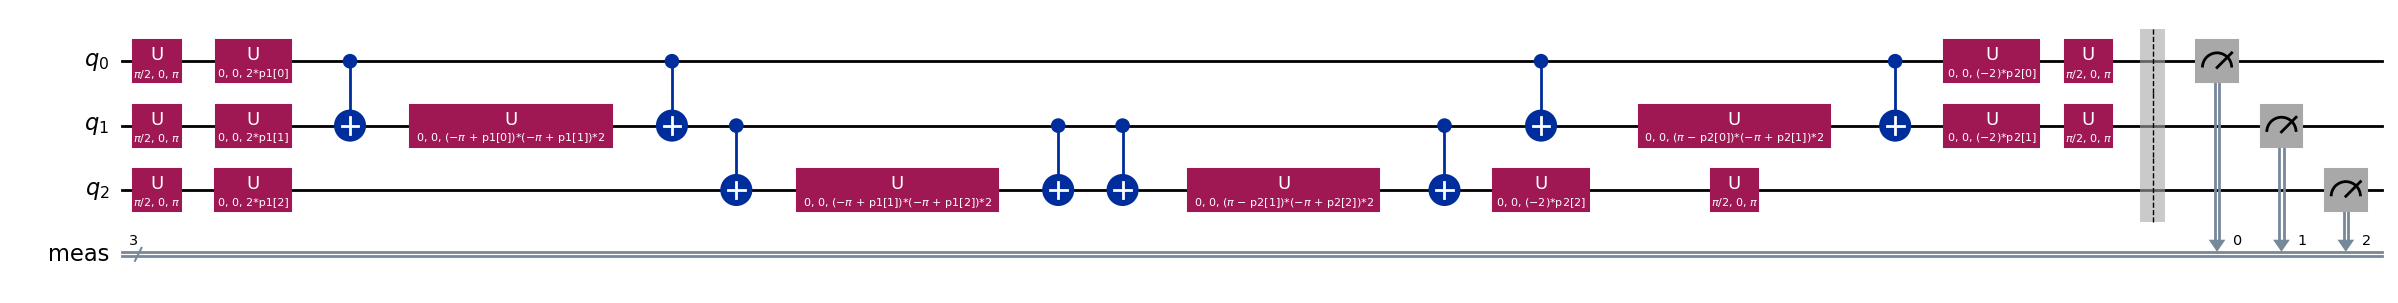

max |sampled - exact| = 0.0100
largest error in units of shot noise = 1.85  (below about 4 is expected)
PASS


In [11]:
from IPython.display import display
from qiskit import transpile
from qiskit_aer import AerSimulator

ideal_simulator = AerSimulator(seed_simulator = config.SEED)
zz_spec = {"kind": "zz", "reps": 1, "entanglement": "linear"}
zz_feature_map = quantum_kernels.build_feature_map(zz_spec)
overlap = quantum_kernels.overlap_template(zz_feature_map)
display(overlap.decompose().draw("mpl", fold = -1))

transpiled_overlap = transpile(overlap, ideal_simulator)
check_points = 0.25 * check_rng.uniform(0, np.pi, (8, 3))
shots = 8192
sampled = quantum_kernels.sampled_gram(transpiled_overlap, ideal_simulator, check_points, shots = shots, seed = config.SEED)
exact = quantum_kernels.exact_gram(zz_spec, check_points)
shot_noise = np.sqrt(np.clip(exact * (1 - exact), 1e-12, None) / shots)
largest_ratio = np.max(np.abs(sampled - exact) / np.maximum(shot_noise, 1 / shots))
print(f"max |sampled - exact| = {np.abs(sampled - exact).max():.4f}")
print(f"largest error in units of shot noise = {largest_ratio:.2f}  (below about 4 is expected)")
print("PASS" if largest_ratio < 5 else "CHECK")

## 6. Noisy simulator and fake IBM device

In [12]:
noisy = quantum_kernels.noisy_simulator(one_qubit_error = 0.001, two_qubit_error = 0.01, readout_error = 0.02)
noisy_overlap = quantum_kernels.transpile_for_simulation(overlap)
noisy_gram = quantum_kernels.sampled_gram(noisy_overlap, noisy, check_points, shots = 4096,
                                          seed = config.SEED, include_diagonal = True)
print("noisy diagonal (exactly 1 without noise):", np.round(np.diag(noisy_gram), 3))
exact_mean = metrics.kernel_diagnostics(exact)["mean_offdiag"]
noisy_mean = metrics.kernel_diagnostics(noisy_gram)["mean_offdiag"]
print(f"mean off-diagonal  exact {exact_mean:.4f}   noisy {noisy_mean:.4f}")
print("fitted global depolarizing lambda:", round(quantum_kernels.global_depolarizing_fit(noisy_gram, exact), 4))

noisy diagonal (exactly 1 without noise): [0.892 0.903 0.905 0.896 0.9   0.893 0.888 0.899]
mean off-diagonal  exact 0.2060   noisy 0.1933
fitted global depolarizing lambda: 0.8804


In [13]:
try:
    fake_backend = quantum_kernels.fake_device_backend()
    print("Fake device:", fake_backend.name, "with", fake_backend.num_qubits, "qubits")
except ImportError as error:
    print("No fake backend available:", error)

Fake device: fake_fez with 156 qubits


## 7. Circuit resources of each feature map (simulation basis rz, sx, x, cx)

In [14]:
resource_rows = []
for spec in specs_to_check:
    overlap_circuit = quantum_kernels.overlap_template(quantum_kernels.build_feature_map(spec))
    resources = quantum_kernels.circuit_resources(quantum_kernels.transpile_for_simulation(overlap_circuit))
    resource_rows.append({"feature_map": quantum_kernels.spec_name(spec), **resources})
resource_table = pd.DataFrame(resource_rows)
print(resource_table.to_string(index = False))
resource_table.to_csv(config.section_results_dir(config.MAIN_SECTION, "resources") / "overlap_circuit_resources_sim_basis.csv", index = False)

      feature_map  qubits_used  depth  two_qubit_gates  total_gates
            angle            3      7                0           18
      z_r1_linear            3      9                0           24
      z_r2_linear            3     17                0           48
     zz_r1_linear            3     19                6           34
     zz_r2_linear            3     39               14           70
     zz_r3_linear            3     59               22          106
       zz_r1_full            3     25               10           40
       zz_r2_full            3     51               22           82
pauli_zzz_r1_full            3     33               16           48


All checks done. Next: `01_data/01_data_audit_and_fixed_splits.ipynb`.